# CO2.1 Exploring Block Attention Mechanisms
* Shafer Arjun Tagorda

In [1]:
%pip install -q torch torchvision torchaudio matplotlib scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, time, random, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, classification_report)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

PyTorch 2.14.0+cu130 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
DATA_DIR    = "/home/arjun/lli-pedestrian/data/llvip_cls"
IMG_SIZE    = 32       
BATCH_SIZE  = 64
EPOCHS      = 10       
LR          = 5e-4
SEED        = 42
TEST_SPLIT  = 0.2      
OUT_DIR     = Path("outputs")

EXPERIMENTS = dict(lr=True, r=True, k=True, M=True, depth=True, position=True)


OUT_DIR.mkdir(exist_ok=True)
NUM_WORKERS = 0 if os.name == "nt" else 2  

In [4]:
tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])


def get_targets(ds):
    if isinstance(ds, Subset):
        return np.array(ds.dataset.targets)[ds.indices]
    return np.array(ds.targets)


def load_data():
    if DATA_DIR is None:
        trainset = datasets.CIFAR10("./data", train=True,  download=True, transform=tf)
        testset  = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
        return trainset, testset, list(trainset.classes)

    root = Path(DATA_DIR)
    test_dir = next((root / n for n in ("test", "val", "valid") if (root / n).is_dir()), None)
    if (root / "train").is_dir() and test_dir is not None:
        trainset = datasets.ImageFolder(root / "train", transform=tf)
        testset  = datasets.ImageFolder(test_dir, transform=tf)
        assert trainset.classes == testset.classes, "train/test class folders differ"
        return trainset, testset, trainset.classes

    full = datasets.ImageFolder(root, transform=tf)
    idx = np.arange(len(full))
    tr, te = train_test_split(idx, test_size=TEST_SPLIT, stratify=full.targets, random_state=SEED)
    return Subset(full, tr), Subset(full, te), full.classes


trainset, testset, classes = load_data()
NUM_CLASSES = len(classes)
print(f"{NUM_CLASSES} classes: {classes}")
print(f"train: {len(trainset)} images | test: {len(testset)} images")
print("train images per class:", dict(zip(classes, np.bincount(get_targets(trainset), minlength=NUM_CLASSES).tolist())))
print("test  images per class:", dict(zip(classes, np.bincount(get_targets(testset),  minlength=NUM_CLASSES).tolist())))

train_loader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
test_loader  = DataLoader(testset, batch_size=256, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

2 classes: ['background', 'person']
train: 68256 images | test: 16604 images
train images per class: {'background': 34128, 'person': 34128}
test  images per class: {'background': 8302, 'person': 8302}


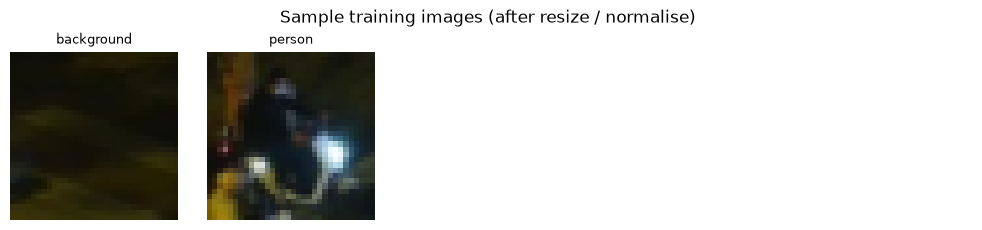

batch tensor: (64, 3, 32, 32) (batch, channels, height, width)


In [ ]:
def show_samples(ds, n=10):
    targets = get_targets(ds)
    rng = np.random.RandomState(SEED)
    cls_ids = rng.choice(NUM_CLASSES, size=min(n, NUM_CLASSES), replace=False) if NUM_CLASSES > n else np.arange(NUM_CLASSES)
    idxs = [int(rng.choice(np.where(targets == c)[0])) for c in cls_ids]
    rows = math.ceil(len(idxs) / 5)
    fig, axes = plt.subplots(rows, 5, figsize=(10, 2.3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idxs):
        img, y = ds[i]
        ax.imshow((img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy(), interpolation="nearest")
        ax.set_title(classes[y], fontsize=9)
    plt.suptitle("Sample training images (after resize / normalise)")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "dataset_samples.png", dpi=150)
    plt.show()


show_samples(trainset)
xb, yb = next(iter(train_loader))
print("batch tensor:", tuple(xb.shape), "(batch, channels, height, width)")

In [ ]:
class SEBlock(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)                     
        self.fc = nn.Sequential(                                  
            nn.Conv2d(c, h, 1), nn.ReLU(inplace=True),
            nn.Conv2d(h, c, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(self.pool(x))


class ECABlock(nn.Module):
    def __init__(self, c, k=3):
        super().__init__()
        assert k % 2 == 1, "k must be odd"
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k, padding=k // 2, bias=False)
        self.sig = nn.Sigmoid()

    def forward(self, x):
        y = self.pool(x)                        
        y = y.squeeze(-1).transpose(-1, -2)     
        y = self.conv(y)                       
        y = y.transpose(-1, -2).unsqueeze(-1)   
        return x * self.sig(y)


class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(h, c, 1, bias=False))

    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1))
        m = self.mlp(F.adaptive_max_pool2d(x, 1))
        return torch.sigmoid(a + m)             


class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)

    def forward(self, x):
        a = x.mean(dim=1, keepdim=True)         
        m = x.amax(dim=1, keepdim=True)        
        return torch.sigmoid(self.conv(torch.cat([a, m], 1)))


class CBAM(nn.Module):
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.ca = ChannelAttention(c, r)
        self.sa = SpatialAttention(k)

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x


class BAM(nn.Module):
    def __init__(self, c, r=16, dilation=4):
        super().__init__()
        h = max(c // r, 4)
        self.ca = nn.Sequential(                                   
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(c, h, 1), nn.ReLU(inplace=True),
            nn.Conv2d(h, c, 1))
        self.sa = nn.Sequential(                                   
            nn.Conv2d(c, h, 1), nn.BatchNorm2d(h), nn.ReLU(inplace=True),
            nn.Conv2d(h, h, 3, padding=dilation, dilation=dilation), nn.BatchNorm2d(h), nn.ReLU(inplace=True),
            nn.Conv2d(h, h, 3, padding=dilation, dilation=dilation), nn.BatchNorm2d(h), nn.ReLU(inplace=True),
            nn.Conv2d(h, 1, 1))
        self.sig = nn.Sigmoid()

    def forward(self, x):
        return x + x * self.sig(self.ca(x) + self.sa(x))


class SKBlock(nn.Module):
    def __init__(self, c, M=2, r=16):
        super().__init__()
        self.M, self.c = M, c
        d = max(c // r, 8)
        self.convs = nn.ModuleList([
            nn.Sequential(nn.Conv2d(c, c, 3 + i * 2, padding=(3 + i * 2) // 2, bias=False),
                          nn.BatchNorm2d(c), nn.ReLU(inplace=True))
            for i in range(M)])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(nn.Linear(c, d), nn.ReLU(inplace=True), nn.Linear(d, c * M))

    def forward(self, x):
        feats = torch.stack([conv(x) for conv in self.convs], dim=1)   
        s = self.pool(feats.sum(dim=1)).flatten(1)                     
        w = self.fc(s).view(-1, self.M, self.c)                        
        w = torch.softmax(w, dim=1).unsqueeze(-1).unsqueeze(-1)        
        return (feats * w).sum(dim=1)                                  


ATT_NAMES = {"none": "Baseline", "se": "SE", "eca": "ECA", "cbam": "CBAM", "bam": "BAM", "sk": "SK"}


def get_attention(name, c, **kw):
    if name == "none": return nn.Identity()
    if name == "se":   return SEBlock(c, **kw)
    if name == "eca":  return ECABlock(c, **kw)
    if name == "cbam": return CBAM(c, **kw)
    if name == "bam":  return BAM(c, **kw)
    if name == "sk":   return SKBlock(c, **kw)
    raise ValueError(name)


for _n in ["se", "eca", "cbam", "bam", "sk"]:
    _blk = get_attention(_n, 32)
    _x = torch.randn(4, 32, 16, 16, requires_grad=True)
    _y = _blk(_x); _y.sum().backward()
    assert _y.shape == _x.shape and _x.grad is not None
    print(f"{ATT_NAMES[_n]:5s} ok | out {tuple(_y.shape)} | params {sum(p.numel() for p in _blk.parameters()):,}")

SE    ok | out (4, 32, 16, 16) | params 292
ECA   ok | out (4, 32, 16, 16) | params 3
CBAM  ok | out (4, 32, 16, 16) | params 354
BAM   ok | out (4, 32, 16, 16) | params 749
SK    ok | out (4, 32, 16, 16) | params 35,784


In [7]:
class AttentionCNN(nn.Module):
    def __init__(self, attn="none", num_classes=10, img_size=32, channels=(32, 64),
                 position="after_relu", **attn_kw):
        super().__init__()
        layers, in_c = [], 3
        for out_c in channels:
            conv, bn, act, pool = nn.Conv2d(in_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True), nn.MaxPool2d(2)
            att = get_attention(attn, out_c, **attn_kw)           # <- the attention slot
            if position == "after_relu":    layers += [conv, bn, act, att, pool]   # default
            elif position == "before_relu": layers += [conv, bn, att, act, pool]
            elif position == "after_pool":  layers += [conv, bn, act, pool, att]
            else: raise ValueError(position)
            in_c = out_c
        self.features = nn.Sequential(*layers)

        self.eval()
        with torch.no_grad():                                    # infer flattened size
            flat = self.features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.train()
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(flat, 128), nn.ReLU(inplace=True),
                                        nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print("=== Baseline: parts of the base CNN ===")
print(AttentionCNN("none", NUM_CLASSES, IMG_SIZE))
print("\n=== Same CNN with SE: note the SEBlock slots ===")
print(AttentionCNN("se", NUM_CLASSES, IMG_SIZE).features)

=== Baseline: parts of the base CNN ===
AttentionCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Identity()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Identity()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

=== Same CNN with SE: note the SEBlo

In [ ]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    tot_loss, n, ys, ps, fwd = 0.0, 0, [], [], 0.0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        if device.type == "cuda": torch.cuda.synchronize()
        t = time.perf_counter()
        out = model(x)
        if device.type == "cuda": torch.cuda.synchronize()
        fwd += time.perf_counter() - t
        tot_loss += loss_fn(out, y).item() * y.size(0); n += y.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return tot_loss / n, float((ys == ps).mean()), ys, ps, fwd


def train_and_eval(name, model, train_loader, test_loader, epochs=EPOCHS, lr=LR, verbose=True):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[])
    train_time = 0.0

    for ep in range(epochs):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        run_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0); correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
        if device.type == "cuda": torch.cuda.synchronize()
        ep_time = time.perf_counter() - t0
        train_time += ep_time

        te_loss, te_acc, _, _, _ = evaluate(model, test_loader, loss_fn)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["test_loss"].append(te_loss);       hist["test_acc"].append(te_acc)
        if verbose:
            print(f"[{name:8s}] epoch {ep+1:2d}/{epochs} | train loss {run_loss/n:.4f} acc {correct/n:.4f} "
                  f"| test loss {te_loss:.4f} acc {te_acc:.4f} | {ep_time:.1f}s")

    _, acc, y_true, y_pred, fwd = evaluate(model, test_loader, loss_fn)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(name=name, accuracy=acc, precision=p, recall=r, f1=f1,
                cm=confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
                y_true=y_true, y_pred=y_pred, history=hist,
                params=count_params(model), train_time=train_time, sec_per_epoch=train_time / epochs,
                infer_ms=1000 * fwd / len(y_true))


def run(name, attn, lr=LR, epochs=EPOCHS, verbose=True, **kw):
    set_seed(SEED)                     
    model = AttentionCNN(attn, NUM_CLASSES, IMG_SIZE, **kw)
    return train_and_eval(name, model, train_loader, test_loader, epochs, lr, verbose)

In [9]:
results = {}
for key in ["none", "se", "eca", "cbam", "bam", "sk"]:
    results[ATT_NAMES[key]] = run(ATT_NAMES[key], key)
    print()

[Baseline] epoch  1/10 | train loss 0.3786 acc 0.8262 | test loss 0.4159 acc 0.8109 | 58.2s
[Baseline] epoch  2/10 | train loss 0.2698 acc 0.8864 | test loss 0.6025 acc 0.7570 | 31.0s
[Baseline] epoch  3/10 | train loss 0.2310 acc 0.9058 | test loss 0.4721 acc 0.7990 | 39.7s
[Baseline] epoch  4/10 | train loss 0.2053 acc 0.9185 | test loss 0.3940 acc 0.8341 | 37.9s
[Baseline] epoch  5/10 | train loss 0.1808 acc 0.9294 | test loss 0.4962 acc 0.8161 | 37.2s
[Baseline] epoch  6/10 | train loss 0.1661 acc 0.9343 | test loss 0.6351 acc 0.7757 | 29.9s
[Baseline] epoch  7/10 | train loss 0.1534 acc 0.9413 | test loss 0.3856 acc 0.8460 | 41.2s
[Baseline] epoch  8/10 | train loss 0.1385 acc 0.9468 | test loss 0.4818 acc 0.8310 | 39.4s
[Baseline] epoch  9/10 | train loss 0.1301 acc 0.9499 | test loss 0.4019 acc 0.8533 | 38.0s
[Baseline] epoch 10/10 | train loss 0.1223 acc 0.9533 | test loss 0.4298 acc 0.8458 | 28.9s

[SE      ] epoch  1/10 | train loss 0.3701 acc 0.8296 | test loss 0.4380 acc 0.

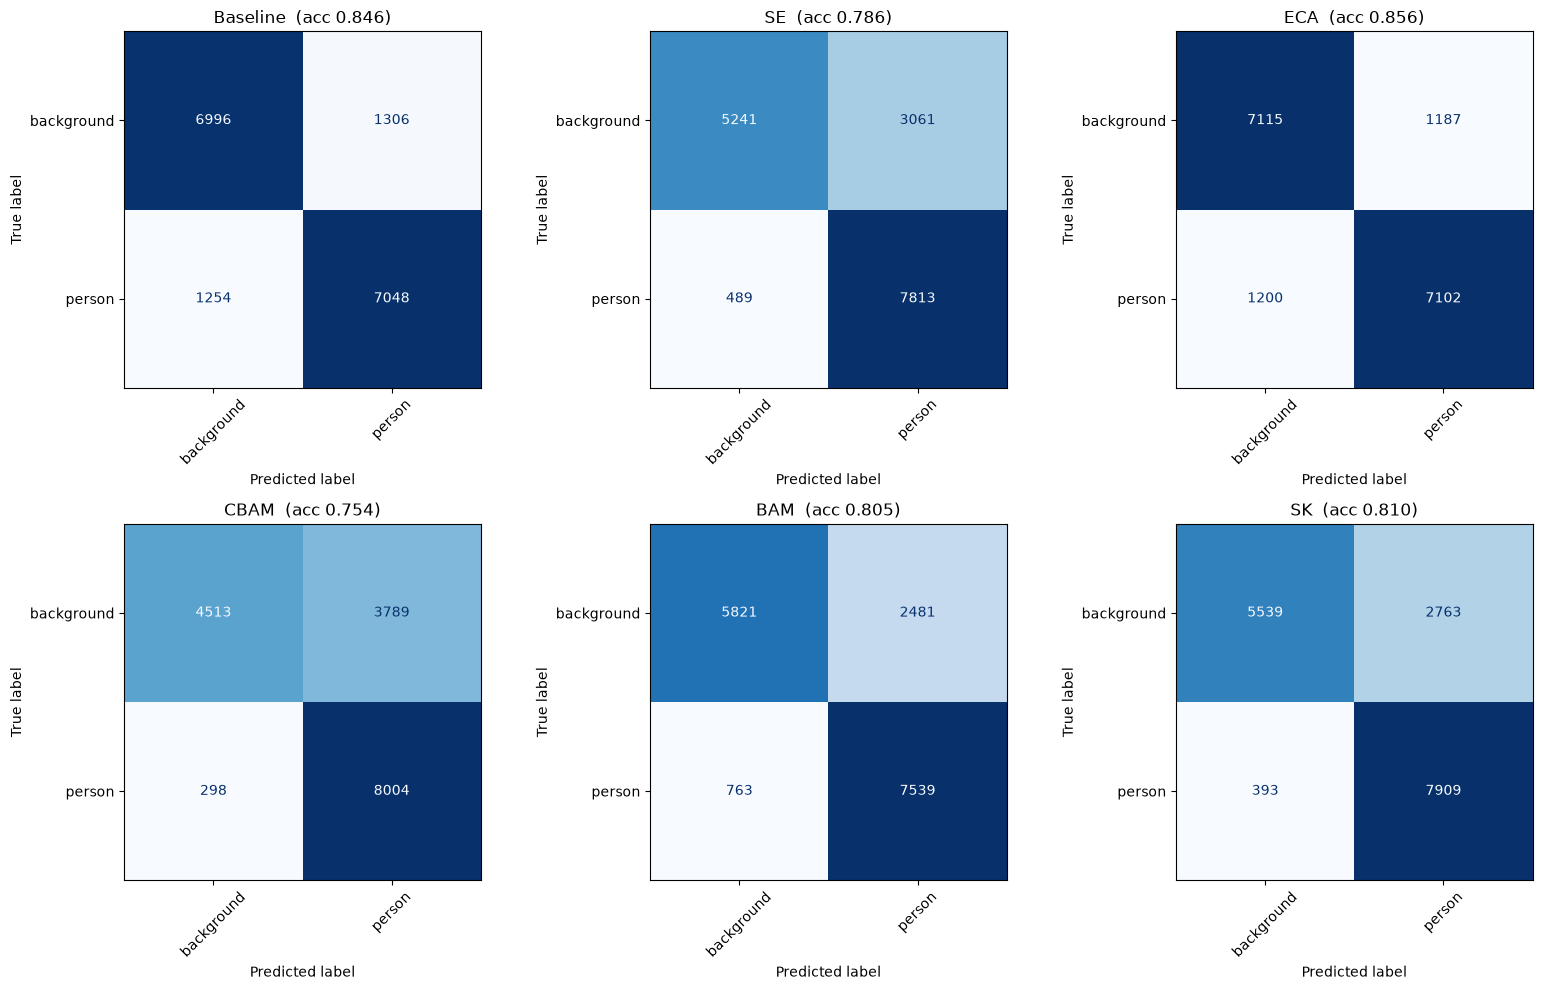

In [ ]:
names = list(results)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, nm in zip(axes.flat, names):
    ConfusionMatrixDisplay(results[nm]["cm"], display_labels=classes).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45, include_values=NUM_CLASSES <= 12)
    ax.set_title(f"{nm}  (acc {results[nm]['accuracy']:.3f})")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices_all.png", dpi=150)
plt.show()

for nm in names:
    f, a = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(results[nm]["cm"], display_labels=classes).plot(
        ax=a, cmap="Blues", colorbar=False, xticks_rotation=45, include_values=NUM_CLASSES <= 12)
    a.set_title(f"Confusion matrix: {nm}")
    f.tight_layout(); f.savefig(OUT_DIR / f"cm_{nm.lower()}.png", dpi=150); plt.close(f)

In [11]:
def to_row(r, **extra):
    return {"Model": r["name"], "Accuracy": r["accuracy"], "Precision": r["precision"],
            "Recall": r["recall"], "F1": r["f1"], "Params": r["params"],
            "Train time (s)": r["train_time"], "s/epoch": r["sec_per_epoch"],
            "Inference (ms/img)": r["infer_ms"], **extra}


main_df = pd.DataFrame([to_row(r) for r in results.values()])
main_df.to_csv(OUT_DIR / "main_results.csv", index=False)
display(main_df.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
                              "Params": "{:,}", "Train time (s)": "{:.1f}", "s/epoch": "{:.2f}",
                              "Inference (ms/img)": "{:.4f}"}).highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1"], color="#cfe8cf"))

print("Per-class report for each model (saved to outputs/classification_reports.txt):")
with open(OUT_DIR / "classification_reports.txt", "w") as fh:
    for nm, r in results.items():
        rep = classification_report(r["y_true"], r["y_pred"], target_names=classes, zero_division=0, digits=3)
        fh.write(f"===== {nm} =====\n{rep}\n")
        print(f"===== {nm} =====\n{rep}")

,Model,Accuracy,Precision,Recall,F1,Params,Train time (s),s/epoch,Inference (ms/img)
0,Baseline,0.8458,0.8458,0.8458,0.8458,"544,258",381.4,38.14,0.0453
1,SE,0.7862,0.8166,0.7862,0.7809,"545,130",365.5,36.55,0.0722
2,ECA,0.8562,0.8562,0.8562,0.8562,"544,264",366.5,36.65,0.0345
3,CBAM,0.7539,0.8084,0.7539,0.7425,"545,222",401.4,40.14,0.0586
4,BAM,0.8046,0.8183,0.8046,0.8025,"546,172",412.3,41.23,0.0580
5,SK,0.8099,0.8374,0.8099,0.8060,"721,234",405.5,40.55,0.0942


Per-class report for each model (saved to outputs/classification_reports.txt):
===== Baseline =====
              precision    recall  f1-score   support

  background      0.848     0.843     0.845      8302
      person      0.844     0.849     0.846      8302

    accuracy                          0.846     16604
   macro avg      0.846     0.846     0.846     16604
weighted avg      0.846     0.846     0.846     16604

===== SE =====
              precision    recall  f1-score   support

  background      0.915     0.631     0.747      8302
      person      0.719     0.941     0.815      8302

    accuracy                          0.786     16604
   macro avg      0.817     0.786     0.781     16604
weighted avg      0.817     0.786     0.781     16604

===== ECA =====
              precision    recall  f1-score   support

  background      0.856     0.857     0.856      8302
      person      0.857     0.855     0.856      8302

    accuracy                          0.856     166

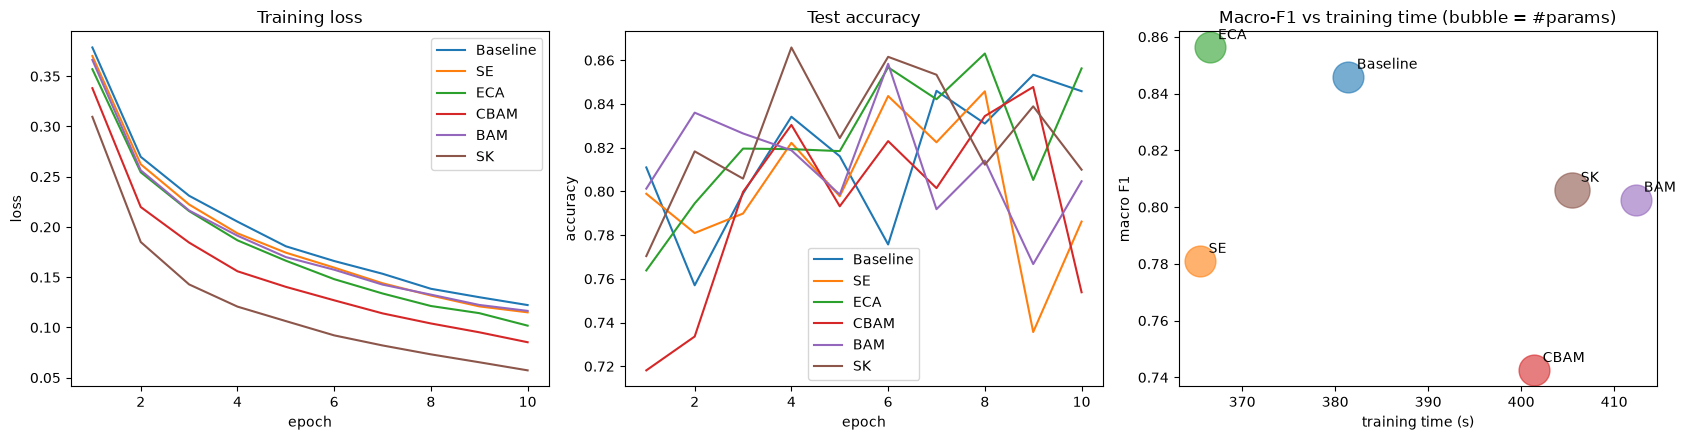

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for nm, r in results.items():
    ep = range(1, len(r["history"]["train_loss"]) + 1)
    axes[0].plot(ep, r["history"]["train_loss"], label=nm)
    axes[1].plot(ep, r["history"]["test_acc"], label=nm)
axes[0].set(title="Training loss", xlabel="epoch", ylabel="loss")
axes[1].set(title="Test accuracy", xlabel="epoch", ylabel="accuracy")
axes[0].legend(); axes[1].legend()

for nm, r in results.items():
    axes[2].scatter(r["train_time"], r["f1"], s=r["params"] / max(m["params"] for m in results.values()) * 600 + 40, alpha=.6)
    axes[2].annotate(nm, (r["train_time"], r["f1"]), textcoords="offset points", xytext=(6, 6))
axes[2].set(title="Macro-F1 vs training time (bubble = #params)", xlabel="training time (s)", ylabel="macro F1")
plt.tight_layout(); plt.savefig(OUT_DIR / "curves_and_tradeoff.png", dpi=150); plt.show()

In [ ]:
base = results["Baseline"]
print(f"{'Model':9s} {'dAcc (pts)':>10s} {'dF1 (pts)':>10s} {'dParams':>9s} {'dTime':>8s}")
for nm, r in results.items():
    if nm == "Baseline": continue
    print(f"{nm:9s} {100*(r['accuracy']-base['accuracy']):+10.2f} {100*(r['f1']-base['f1']):+10.2f} "
          f"{100*(r['params']/base['params']-1):+8.1f}% {100*(r['train_time']/base['train_time']-1):+7.1f}%")
best = max(results.values(), key=lambda r: r["f1"])
print(f"\nBest macro-F1: {best['name']} ({best['f1']:.4f}) | fastest: {min(results.values(), key=lambda r: r['train_time'])['name']}")
print("NOTE: a single seed on one test set. Gaps of ~1 point or less can be noise (see Step 5 / further experiments).")

Model     dAcc (pts)  dF1 (pts)   dParams    dTime
SE             -5.96      -6.49     +0.2%    -4.2%
ECA            +1.04      +1.04     +0.0%    -3.9%
CBAM           -9.20     -10.33     +0.2%    +5.2%
BAM            -4.12      -4.33     +0.4%    +8.1%
SK             -3.59      -3.98    +32.5%    +6.3%

Best macro-F1: ECA (0.8562) | fastest: SE
NOTE: a single seed on one test set. Gaps of ~1 point or less can be noise (see Step 5 / further experiments).


In [14]:
exp_rows = []
ATT5 = ["se", "eca", "cbam", "bam", "sk"]


def exp_row(group, module, config, r):
    return {"Group": group, "Module": module, "Config": config, "Accuracy": r["accuracy"],
            "Precision": r["precision"], "Recall": r["recall"], "F1": r["f1"],
            "Params": r["params"], "Train time (s)": r["train_time"]}


def run_exp(group, attn, config, lr=LR, **kw):
    r = run(f"{ATT_NAMES[attn]}|{config}", attn, lr=lr, verbose=False, **kw)
    exp_rows.append(exp_row(group, ATT_NAMES[attn], config, r))
    print(f"{group:8s} {ATT_NAMES[attn]:8s} {config:26s} acc {r['accuracy']:.4f}  F1 {r['f1']:.4f}  "
          f"params {r['params']:,}  time {r['train_time']:.1f}s")


def show_group(group):
    sub = pd.DataFrame([x for x in exp_rows if x["Group"] == group])
    if sub.empty: return
    refs = pd.DataFrame([exp_row(group, m, "default (main run)", results[m]) for m in sub["Module"].unique()])
    df = pd.concat([refs, sub]).sort_values(["Module", "Config"], kind="stable").reset_index(drop=True)
    display(df.drop(columns="Group").style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1"]} |
                                                    {"Params": "{:,}", "Train time (s)": "{:.1f}"}))

In [15]:
if EXPERIMENTS["lr"]:
    for a in ATT5:
        for lr in (1e-3, 1e-4):
            run_exp("lr", a, f"lr={lr:g}", lr=lr)
    show_group("lr")

lr       SE       lr=0.001                   acc 0.8292  F1 0.8278  params 545,130  time 396.8s
lr       SE       lr=0.0001                  acc 0.8320  F1 0.8319  params 545,130  time 156.9s
lr       ECA      lr=0.001                   acc 0.8653  F1 0.8652  params 544,264  time 137.6s
lr       ECA      lr=0.0001                  acc 0.8278  F1 0.8275  params 544,264  time 134.0s
lr       CBAM     lr=0.001                   acc 0.7815  F1 0.7757  params 545,222  time 146.1s
lr       CBAM     lr=0.0001                  acc 0.8048  F1 0.8027  params 545,222  time 144.0s
lr       BAM      lr=0.001                   acc 0.8082  F1 0.8052  params 546,172  time 149.6s
lr       BAM      lr=0.0001                  acc 0.8044  F1 0.8026  params 546,172  time 151.7s
lr       SK       lr=0.001                   acc 0.8244  F1 0.8213  params 721,234  time 141.2s
lr       SK       lr=0.0001                  acc 0.7883  F1 0.7821  params 721,234  time 141.3s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,BAM,default (main run),0.8046,0.8183,0.8046,0.8025,"546,172",412.3
1,BAM,lr=0.0001,0.8044,0.8157,0.8044,0.8026,"546,172",151.7
2,BAM,lr=0.001,0.8082,0.8282,0.8082,0.8052,"546,172",149.6
3,CBAM,default (main run),0.7539,0.8084,0.7539,0.7425,"545,222",401.4
4,CBAM,lr=0.0001,0.8048,0.8183,0.8048,0.8027,"545,222",144.0
5,CBAM,lr=0.001,0.7815,0.8137,0.7815,0.7757,"545,222",146.1
6,ECA,default (main run),0.8562,0.8562,0.8562,0.8562,"544,264",366.5
7,ECA,lr=0.0001,0.8278,0.8304,0.8278,0.8275,"544,264",134.0
8,ECA,lr=0.001,0.8653,0.8659,0.8653,0.8652,"544,264",137.6
9,SE,default (main run),0.7862,0.8166,0.7862,0.7809,"545,130",365.5


In [16]:
if EXPERIMENTS["r"]:
    for a in ["se", "cbam", "bam"]:
        for r_ in (8, 32):
            run_exp("r", a, f"r={r_}", r=r_)
    show_group("r")

r        SE       r=8                        acc 0.8507  F1 0.8504  params 545,646  time 130.9s
r        SE       r=32                       acc 0.7862  F1 0.7809  params 545,130  time 133.5s
r        CBAM     r=8                        acc 0.8534  F1 0.8532  params 545,734  time 135.0s
r        CBAM     r=32                       acc 0.7539  F1 0.7425  params 545,222  time 135.3s
r        BAM      r=8                        acc 0.8305  F1 0.8295  params 547,848  time 138.6s
r        BAM      r=32                       acc 0.8046  F1 0.8025  params 546,172  time 132.0s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,BAM,default (main run),0.8046,0.8183,0.8046,0.8025,"546,172",412.3
1,BAM,r=32,0.8046,0.8183,0.8046,0.8025,"546,172",132.0
2,BAM,r=8,0.8305,0.8385,0.8305,0.8295,"547,848",138.6
3,CBAM,default (main run),0.7539,0.8084,0.7539,0.7425,"545,222",401.4
4,CBAM,r=32,0.7539,0.8084,0.7539,0.7425,"545,222",135.3
5,CBAM,r=8,0.8534,0.8556,0.8534,0.8532,"545,734",135.0
6,SE,default (main run),0.7862,0.8166,0.7862,0.7809,"545,130",365.5
7,SE,r=32,0.7862,0.8166,0.7862,0.7809,"545,130",133.5
8,SE,r=8,0.8507,0.8532,0.8507,0.8504,"545,646",130.9


In [17]:
if EXPERIMENTS["k"]:
    for k_ in (5, 7):
        run_exp("k", "eca", f"k={k_}", k=k_)
    show_group("k")

k        ECA      k=5                        acc 0.8137  F1 0.8114  params 544,268  time 130.0s
k        ECA      k=7                        acc 0.8640  F1 0.8639  params 544,272  time 139.8s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,ECA,default (main run),0.8562,0.8562,0.8562,0.8562,"544,264",366.5
1,ECA,k=5,0.8137,0.8299,0.8137,0.8114,"544,268",130.0
2,ECA,k=7,0.8640,0.8646,0.8640,0.8639,"544,272",139.8


In [18]:
if EXPERIMENTS["M"]:
    run_exp("M", "sk", "M=3 (3x3,5x5,7x7)", M=3)
    show_group("M")

M        SK       M=3 (3x3,5x5,7x7)          acc 0.8620  F1 0.8608  params 973,170  time 216.5s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,SK,"M=3 (3x3,5x5,7x7)",0.8620,0.8755,0.8620,0.8608,"973,170",216.5
1,SK,default (main run),0.8099,0.8374,0.8099,0.8060,"721,234",405.5


In [19]:
if EXPERIMENTS["depth"]:
    for a in ["none"] + ATT5:
        run_exp("depth", a, "3 blocks (32-64-128)", channels=(32, 64, 128))
    show_group("depth")

depth    Baseline 3 blocks (32-64-128)       acc 0.8580  F1 0.8579  params 356,226  time 133.8s
depth    SE       3 blocks (32-64-128)       acc 0.7578  F1 0.7471  params 359,282  time 126.5s
depth    ECA      3 blocks (32-64-128)       acc 0.8333  F1 0.8312  params 356,235  time 127.0s
depth    CBAM     3 blocks (32-64-128)       acc 0.8546  F1 0.8544  params 359,336  time 136.8s
depth    BAM      3 blocks (32-64-128)       acc 0.8169  F1 0.8137  params 362,581  time 147.2s
depth    SK       3 blocks (32-64-128)       acc 0.8914  F1 0.8913  params 1,094,106  time 172.0s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,BAM,3 blocks (32-64-128),0.8169,0.8402,0.8169,0.8137,"362,581",147.2
1,BAM,default (main run),0.8046,0.8183,0.8046,0.8025,"546,172",412.3
2,Baseline,3 blocks (32-64-128),0.8580,0.8591,0.8580,0.8579,"356,226",133.8
3,Baseline,default (main run),0.8458,0.8458,0.8458,0.8458,"544,258",381.4
4,CBAM,3 blocks (32-64-128),0.8546,0.8556,0.8546,0.8544,"359,336",136.8
5,CBAM,default (main run),0.7539,0.8084,0.7539,0.7425,"545,222",401.4
6,ECA,3 blocks (32-64-128),0.8333,0.8504,0.8333,0.8312,"356,235",127.0
7,ECA,default (main run),0.8562,0.8562,0.8562,0.8562,"544,264",366.5
8,SE,3 blocks (32-64-128),0.7578,0.8105,0.7578,0.7471,"359,282",126.5
9,SE,default (main run),0.7862,0.8166,0.7862,0.7809,"545,130",365.5


In [20]:
if EXPERIMENTS["position"]:
    for a in ATT5:
        for pos in ("before_relu", "after_pool"):
            run_exp("position", a, pos, position=pos)
    show_group("position")

position SE       before_relu                acc 0.8298  F1 0.8284  params 545,130  time 142.8s
position SE       after_pool                 acc 0.8087  F1 0.8062  params 545,130  time 135.4s
position ECA      before_relu                acc 0.8585  F1 0.8582  params 544,264  time 141.1s
position ECA      after_pool                 acc 0.8480  F1 0.8479  params 544,264  time 134.5s
position CBAM     before_relu                acc 0.8062  F1 0.8026  params 545,222  time 125.0s
position CBAM     after_pool                 acc 0.7995  F1 0.7946  params 545,222  time 125.0s
position BAM      before_relu                acc 0.8314  F1 0.8309  params 546,172  time 132.3s
position BAM      after_pool                 acc 0.8522  F1 0.8521  params 546,172  time 124.8s
position SK       before_relu                acc 0.8200  F1 0.8173  params 721,234  time 134.3s
position SK       after_pool                 acc 0.8654  F1 0.8651  params 721,234  time 126.8s


,Module,Config,Accuracy,Precision,Recall,F1,Params,Train time (s)
0,BAM,after_pool,0.8522,0.8531,0.8522,0.8521,"546,172",124.8
1,BAM,before_relu,0.8314,0.8359,0.8314,0.8309,"546,172",132.3
2,BAM,default (main run),0.8046,0.8183,0.8046,0.8025,"546,172",412.3
3,CBAM,after_pool,0.7995,0.8309,0.7995,0.7946,"545,222",125.0
4,CBAM,before_relu,0.8062,0.8306,0.8062,0.8026,"545,222",125.0
5,CBAM,default (main run),0.7539,0.8084,0.7539,0.7425,"545,222",401.4
6,ECA,after_pool,0.8480,0.8494,0.8480,0.8479,"544,264",134.5
7,ECA,before_relu,0.8585,0.8610,0.8585,0.8582,"544,264",141.1
8,ECA,default (main run),0.8562,0.8562,0.8562,0.8562,"544,264",366.5
9,SE,after_pool,0.8087,0.8254,0.8087,0.8062,"545,130",135.4


In [21]:
if exp_rows:
    exp_df = pd.DataFrame(exp_rows)
    exp_df.to_csv(OUT_DIR / "experiment_results.csv", index=False)
    print(f"saved {len(exp_df)} experiment rows to {OUT_DIR / 'experiment_results.csv'}")

saved 35 experiment rows to outputs/experiment_results.csv
